# Haapsalu urban blocks

Self-study project: city blocks and block metrics for Haapsalu (Estonia) with BlocksNet,
and a comparison of OpenStreetMap buildings with official Estonian building data.
See `PLAN.md` for the research questions.

## 1. Data

This section downloads every input layer, brings it to the Estonian metric
coordinate system **EPSG:3301 (L-EST97)**, cuts it to the town boundary and saves it to
`data/*.geojson`. Large raw downloads go to `data/raw/` (not in git).
At the end it writes `data/SOURCES.md` and a check map `data/check_map.png`.

### 1.0 Set-up

Libraries, folders and the download date. Every layer is registered in `SOURCES`,
which is used at the end to write `data/SOURCES.md`.

In [1]:
import hashlib
import json
import time
import urllib.parse
import urllib.request
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import osmnx as ox
import pandas as pd
from shapely import force_2d

CRS = "EPSG:3301"  # L-EST97, Estonian metric CRS
DATA = Path("data")
RAW = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
TODAY = date.today().isoformat()

ox.settings.use_cache = True
ox.settings.cache_folder = str(RAW / "osmnx_cache")

SOURCES = []  # one dict per saved layer or table

LICENCE_MRA = ("Republic of Estonia Land and Spatial Development Board (Maa- ja Ruumiamet) opendata licence "
               "01.01.2025, https://geoportaal.maaruum.ee/opendata-licence")

# Frozen downloads: every source is downloaded once. Raw files are kept in data/raw/ (not in git)
# and reused by later runs. data/download_dates.json (in git) holds the date of the first download.
# To refresh a source, delete its raw file and its date entry, then run the notebook again.
DATES_FILE = DATA / "download_dates.json"
DATES = json.loads(DATES_FILE.read_text(encoding="utf-8")) if DATES_FILE.exists() else {}
LAYER_SOURCE = {"boundary": "ehak_settlements", "osm_roads": "osm_roads", "osm_railways": "osm", "osm_water": "osm",
                "osm_landuse": "osm", "osm_buildings": "osm", "osm_schools": "osm",
                "official_buildings": "etak_ehr_hooned", "ehis_schools": "ehis", "schools": "ehis"}


def stamp(key):
    """Date of the first download of a source; recorded once, never overwritten."""
    if key not in DATES:
        DATES[key] = TODAY
        DATES_FILE.write_text(json.dumps(DATES, indent=2), encoding="utf-8")
    return DATES[key]


def download(url, path):
    """Download url to path once; later runs reuse the file."""
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def save_layer(gdf, name, source, url, licence):
    """Save a layer as data/<name>.geojson and register it in SOURCES."""
    gdf = gdf.to_crs(CRS)
    path = DATA / f"{name}.geojson"
    gdf.to_file(path, driver="GeoJSON")
    SOURCES.append(dict(layer=name, file=str(path.as_posix()), source=source, url=url,
                        licence=licence, date=TODAY if name.startswith('blocks') else stamp(LAYER_SOURCE.get(name, name)),
                        features=len(gdf)))
    print(f"{name}: {len(gdf)} features -> {path}")
    return gdf

### 1.1 Town boundary (official)

Source: Maa- ja Ruumiamet, EHAK administrative and settlement division, layer
"Asustusüksused" (settlement units). We take the settlement **Haapsalu linn**
(EHAK code 1692), not the municipality Haapsalu linn, which since 2017 also includes
the former Ridala vald. The file is already in EPSG:3301.

In [2]:
EHAK_URL = "https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip"
ehak_zip = download(EHAK_URL, RAW / "asustusyksus_shp.zip")

settlements = gpd.read_file(f"zip://{ehak_zip.as_posix()}!asustusyksus.shp")
boundary = settlements[settlements["AKOOD"] == "1692"].to_crs(CRS)
assert len(boundary) == 1 and boundary.iloc[0]["ANIMI"] == "Haapsalu linn"
boundary = boundary[["ANIMI", "AKOOD", "ONIMI", "OKOOD", "EKSPORT", "geometry"]]
boundary["EKSPORT"] = boundary["EKSPORT"].astype(str)

save_layer(boundary, "boundary", "Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), "
           f"Haapsalu linn, AKOOD 1692, export {boundary.iloc[0]['EKSPORT'][:10]}",
           EHAK_URL, LICENCE_MRA + " (the EHAK page itself only says: open data, cite source and date)")
print(f"Area: {boundary.area.iloc[0] / 1e6:.2f} km²")

area = boundary.geometry.iloc[0]          # boundary polygon in EPSG:3301
area_wgs = boundary.to_crs(4326).geometry.iloc[0]  # the same in WGS84, for OSM queries

boundary: 1 features -> data\boundary.geojson
Area: 11.02 km²


### 1.2 OpenStreetMap layers

Downloaded with `osmnx` for the boundary polygon, using the same tags as the BlocksNet
example `examples/pipeline.ipynb`. Lines and areas (roads, water, land use) are cut
exactly at the boundary. Buildings and schools are **not cut**: an object is kept whole
if its inside point lies in the town, so footprint areas stay correct for the comparison
with the official buildings. Only useful columns are kept.

In [3]:
OSM_URL = "https://www.openstreetmap.org (Overpass API via osmnx)"
OSM_LICENCE = "ODbL 1.0, © OpenStreetMap contributors"


def osm(tags, geom_types, columns, cut=True, attempts=6):
    """Fetch OSM features inside the boundary, keep given geometry types and columns.

    The public Overpass server is sometimes busy, so failed requests are retried
    with a growing pause (30 s, 60 s, 120 s, ...).
    """
    raw = RAW / f"osm_{hashlib.md5(json.dumps(tags, sort_keys=True).encode()).hexdigest()[:10]}.parquet"
    if raw.exists():  # frozen: reuse the first download
        gdf = gpd.read_parquet(raw)
    else:
        for i in range(attempts):
            try:
                gdf = ox.features_from_polygon(area_wgs, tags)
                break
            except ox._errors.InsufficientResponseError:
                return gpd.GeoDataFrame(columns=["osm_id", *columns, "geometry"], geometry="geometry", crs=CRS)
            except ox._errors.ResponseStatusCodeError as e:
                if i == attempts - 1:
                    raise
                print(f"Overpass busy, retry in {30 * 2 ** i} s: {str(e)[:60]}")
                time.sleep(30 * 2 ** i)
        gdf.to_parquet(raw)
    gdf = gdf.reset_index()
    gdf["osm_id"] = gdf["element"] + "/" + gdf["id"].astype(str)
    gdf = gdf[gdf.geom_type.isin(geom_types)]
    gdf = gdf[["osm_id", *[c for c in columns if c in gdf.columns], "geometry"]].to_crs(CRS)
    if cut:
        gdf = gdf.clip(area)
        gdf = gdf[~gdf.is_empty]
    else:
        gdf = gdf[gdf.representative_point().within(area)]
    return gdf.reset_index(drop=True)


LINES = ["LineString", "MultiLineString"]
POLYS = ["Polygon", "MultiPolygon"]

Tags from the BlocksNet example: roads, railways and water. One road type is added to the
BlocksNet list: **`highway=service`** (yard, access and parking roads), because the BlocksNet
list misses almost all of them. `footway`, `path`, `cycleway` and `steps` are deliberately not
downloaded: footpaths would cut the town into narrow strips.

**Railway is excluded from block cutting.** The Haapsalu line is closed, but OSM still has
a few segments tagged `railway=rail` near the old station. They are saved to
`data/osm_railways.geojson` for transparency, and `RAILWAYS_FOR_CUTTING` is an empty layer,
so the closed line does not split blocks in section 2.

In [4]:
road_tags = {"highway": ["construction", "crossing", "living_street", "motorway", "motorway_link",
                         "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
                         "residential", "road", "secondary", "secondary_link", "service", "services", "tertiary",
                         "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
                         "turning_loop", "unclassified"],
             "service": ["living_street", "emergency_access"]}
water_tags = {"riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True,
              "pond": True, "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"],
              "landuse": "basin", "water": "lake"}

roads = osm(road_tags, LINES, ["highway", "service", "name"])
railways = osm({"railway": "rail"}, LINES, ["railway", "name"])
water = osm(water_tags, POLYS + LINES, ["natural", "water", "waterway", "landuse", "name"])

save_layer(roads, "osm_roads", "OpenStreetMap, highway=* (BlocksNet example tags + highway=service; "
           "no footway, path, cycleway, steps)", OSM_URL, OSM_LICENCE)
save_layer(railways, "osm_railways", "OpenStreetMap, railway=rail (closed line; not used for block cutting)",
           OSM_URL, OSM_LICENCE)
RAILWAYS_FOR_CUTTING = railways.iloc[0:0]  # the Haapsalu line is closed: no railway lines cut blocks
save_layer(water, "osm_water", "OpenStreetMap, water tags from the BlocksNet example", OSM_URL, OSM_LICENCE);

osm_roads: 1054 features -> data\osm_roads.geojson
osm_railways: 4 features -> data\osm_railways.geojson
osm_water: 61 features -> data\osm_water.geojson


Land use (`landuse=*`), buildings (`building=*`, with `building:levels`) and schools
(`amenity=school`).

In [5]:
landuse = osm({"landuse": True}, POLYS, ["landuse", "name"])
buildings_osm = osm({"building": True}, POLYS,
                    ["building", "building:levels", "height", "name", "addr:street", "addr:housenumber"],
                    cut=False)
schools_osm = osm({"amenity": "school"}, POLYS + ["Point"], ["amenity", "name", "isced:level", "capacity"],
                  cut=False)

# Remove duplicates: a school polygon lying inside another school polygon with the same name
# (Haapsalu Põhikool is mapped twice: the school grounds and, inside them, a second outline).
key = schools_osm["name"].str.lower()
duplicate = [i for i, g in schools_osm.geometry.items() if g.geom_type != "Point" and any(
    j != i and key[j] == key[i] and h.geom_type != "Point" and h.area > g.area and h.buffer(1).contains(g)
    for j, h in schools_osm.geometry.items())]
print("Removed OSM school duplicates:", schools_osm.loc[duplicate, ["osm_id", "name"]].values.tolist())
schools_osm = schools_osm.drop(index=duplicate).reset_index(drop=True)

save_layer(landuse, "osm_landuse", "OpenStreetMap, landuse=*", OSM_URL, OSM_LICENCE)
save_layer(buildings_osm, "osm_buildings", "OpenStreetMap, building=* (whole buildings, inside point in town)",
           OSM_URL, OSM_LICENCE)
save_layer(schools_osm, "osm_schools", "OpenStreetMap, amenity=school", OSM_URL, OSM_LICENCE);

Removed OSM school duplicates: [['way/859053315', 'Haapsalu põhikool']]
osm_landuse: 344 features -> data\osm_landuse.geojson


osm_buildings: 3885 features -> data\osm_buildings.geojson
osm_schools: 4 features -> data\osm_schools.geojson


### 1.3 Official buildings (ETAK + Building Register)

Source: Maa- ja Ruumiamet WFS, layer `etak_tuletis:etak_ehr_hooned`: ETAK building
footprints enriched with Building Register (EHR) data, including the number of floors
`max_korruste_arv`, height, footprint and net floor area, and use. Only the bounding box
of Haapsalu is requested (in pages of 5 000, the server limit), then buildings whose
inside point lies in the town are kept. Heights in the geometry (Z) are dropped.

Three columns are added for later calculations (nothing else is changed or filled):
- `footprint_m2`: area of the geometry in EPSG:3301 (not the register field `ehitisalune_pind`);
- `floors`: `max_korruste_arv`; if empty, `round(korgus_m / 3)` with a minimum of 1; if both are
  empty, 1;
- `floors_source`: `registry`, `height_3m` or `default_1`.

3 m per floor is a conventional assumption, not a norm. Floors that are not from the registry
are meant for density only, not for population.

A fourth column, `is_dwelling`, marks the buildings that count as dwellings for the population
estimate. The rule: the building is a dwelling if at least one of its uses (`kaos_nimetus`,
repeated entries collapsed) is one of five dwelling uses: `Üksikelamu`, `Muu kolme või enama
korteriga elamu`, `Ridaelamu või kaksikelamu sektsioon (...)`, `Kahe korteriga elamu`,
`Ridaelamu`. The whole building counts, also when it has other uses (shop, office).
Accommodation and institutions (hotels, sanatorium, children's home, care home, holiday and
garden houses) and `Elamu, kooli vms abihoone` (outbuildings) are not dwellings. The text of
`kaos_nimetus` is cut at 500 characters; if the last use of such a text is a fragment of exactly
one known full use, it is read as that use for the classification only. The values in the data
are not changed.

In [6]:
WFS = "https://gsavalik.envir.ee/geoserver/etak_tuletis/wfs"
xmin, ymin, xmax, ymax = boundary.total_bounds
ETAK_RAW = RAW / "etak_ehr_hooned_bbox.geojson"
pages, start = [], 0
while not ETAK_RAW.exists():  # frozen: downloaded only if the raw file is missing
    url = (f"{WFS}?service=WFS&version=2.0.0&request=GetFeature&typeNames=etak_tuletis:etak_ehr_hooned"
           f"&srsName=EPSG:3301&outputFormat=application/json&sortBy=fid&count=5000&startIndex={start}"
           f"&bbox={xmin:.0f},{ymin:.0f},{xmax:.0f},{ymax:.0f},EPSG:3301")
    with urllib.request.urlopen(url) as r:
        page = json.load(r)
    pages += page["features"]
    start += len(page["features"])
    if len(page["features"]) < 5000:
        break

if not ETAK_RAW.exists():
    ETAK_RAW.write_text(json.dumps({"type": "FeatureCollection", "features": pages}), encoding="utf-8")
pages = json.loads(ETAK_RAW.read_text(encoding="utf-8"))["features"]
buildings_off = gpd.GeoDataFrame.from_features(pages, crs=CRS)
buildings_off["geometry"] = force_2d(buildings_off.geometry)
print(f"In bounding box: {len(buildings_off)}")
buildings_off = buildings_off[buildings_off.representative_point().within(area)]
# `fid` is a row number of the server that changes between requests; dropping it and sorting
# the rows gives the same file every time, so git does not see false changes.
buildings_off = (buildings_off.drop(columns="fid").sort_values(["ehr_gid", "etak_id"], na_position="last")
                 .reset_index(drop=True))

# Columns for later calculations. 3 m per floor is a conventional assumption, not a norm.
buildings_off["footprint_m2"] = buildings_off.area.round(1)
registry_floors = buildings_off["max_korruste_arv"]
floors_from_height = (buildings_off["korgus_m"] / 3).round().clip(lower=1)
buildings_off["floors"] = registry_floors.where(registry_floors.notna(), floors_from_height).fillna(1).astype(int)
buildings_off["floors_source"] = np.select([registry_floors.notna(), buildings_off["korgus_m"].notna()],
                                           ["registry", "height_3m"], default="default_1")
print(buildings_off["floors_source"].value_counts().to_string())

# Dwellings for the population estimate (see the text above). Classification only; kaos_nimetus is not changed.
DWELLING_USES = {"Üksikelamu", "Muu kolme või enama korteriga elamu",
                 "Ridaelamu või kaksikelamu sektsioon (juhul kui on oma katus ja sissepääs maapinnalt)",
                 "Kahe korteriga elamu", "Ridaelamu"}
KAOS_LIMIT = 500  # kaos_nimetus is cut at this many characters


def split_uses(text):
    """Uses in a kaos_nimetus text, repeated entries collapsed."""
    parts = []
    for part in text.split(";"):
        part = part.strip()
        if part and part not in parts:
            parts.append(part)
    return parts


texts = buildings_off["kaos_nimetus"].fillna("")
known_uses = {part for t in texts[texts.str.len() < KAOS_LIMIT] for part in split_uses(t)}
tail_stats = {"restored": 0, "ambiguous": 0}


def classify_uses(text):
    parts = split_uses(text)
    if len(text) >= KAOS_LIMIT and parts and parts[-1] not in known_uses:
        candidates = [u for u in known_uses if u.startswith(parts[-1])]
        if len(candidates) == 1:
            parts[-1] = candidates[0]
            tail_stats["restored"] += 1
        else:
            tail_stats["ambiguous"] += 1
    return parts


buildings_off["is_dwelling"] = texts.map(lambda t: any(part in DWELLING_USES for part in classify_uses(t)))
print("Cut texts (500 characters):", int((texts.str.len() >= KAOS_LIMIT).sum()), "| tail restored:", tail_stats["restored"],
      "| tail ambiguous (left as it is):", tail_stats["ambiguous"])
print("Dwellings:", int(buildings_off["is_dwelling"].sum()), "of", len(buildings_off))

save_layer(buildings_off, "official_buildings",
           "Maa- ja Ruumiamet, WFS etak_tuletis:etak_ehr_hooned (ETAK buildings with EHR data), "
           "Haapsalu bounding box, inside point in town",
           WFS, LICENCE_MRA);

In bounding box: 4560
floors_source
registry     2982
height_3m     879
default_1      80
Cut texts (500 characters): 77 | tail restored: 75 | tail ambiguous (left as it is): 2
Dwellings: 1757 of 3941


official_buildings: 3941 features -> data\official_buildings.geojson


### 1.4 Statistics Estonia (census 2021)

Tables from the Statistics Estonia database (PxWeb API) for the settlement unit
Haapsalu linn (code `005601841692L5`), state on 31 December 2021:

- **RL21003**: population by place of residence (settlement), sex and age. Gives the total
  population and the number of children aged 7–18.
- **RL21218**: total area of occupied conventional dwellings.
- **RL21807**: "average area of dwelling per inhabitant" (kept for comparison only).

**Which area per person is used.** The census defines the area of a dwelling in two ways:
the useful floor area inside the outer walls, or the floor area of rooms only. Two published
figures differ a lot: the census results page "Housing arrangements" gives **30.1 m²** per
person for Estonia, RL21807 gives **23.5 m²**. The 30.1 m² figure is the total useful floor
area: it matches the RL21218 total (38.97 million m², the "nearly 39 million m²" on the
results page) divided by the residents. RL21807 is about 76-78 % of that (Estonia, Haapsalu linn), which fits the floor area of rooms only (no kitchen, bathroom, hall); its table has
no footnote saying so, so this part is an inference. BlocksNet estimates population from
footprint × floors, a gross floor area, so the total useful floor area is closer. For
Haapsalu linn it is RL21218 occupied dwelling area / RL21003 population. The denominator
also includes people in institutions, so the value is slightly low (the same calculation
gives 29.3 m² for Estonia against the published 30.1 m²).

**Limitation: gross versus usable floor area.** BlocksNet computes floor area as
footprint × number of floors. This is a *gross* floor area: it includes walls, staircases,
corridors and non-residential floors. The 29.9 m² per person is a *usable* floor area of
dwellings, which is smaller. Dividing a gross area by a usable-area norm overestimates the
population, so the estimated population is expected to be **higher** than the official
9 595. This is stated as a limitation of the method. The parameter is not adjusted to match
the official population; the difference is reported as a check of the model.

In [7]:
STAT = "https://andmed.stat.ee/api/v1/en/stat/"
T_POP = "rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px"
T_AREA = "rahvaloendus/rel2021/elamistingimused/RL21807.px"
HAAPSALU = "005601841692L5"


def pxweb(table, selection):
    """Query a Statistics Estonia table once; later runs reuse the saved answer (frozen)."""
    body = {"query": [{"code": k, "selection": {"filter": "item", "values": v}} for k, v in selection.items()],
            "response": {"format": "json-stat2"}}
    raw = RAW / f"stat_{hashlib.md5(json.dumps([table, body], sort_keys=True).encode()).hexdigest()[:10]}.json"
    if not raw.exists():
        req = urllib.request.Request(STAT + table, json.dumps(body).encode(), {"Content-Type": "application/json"})
        with urllib.request.urlopen(req) as r:
            raw.write_text(json.dumps(json.load(r)), encoding="utf-8")
    return json.loads(raw.read_text(encoding="utf-8"))


meta = json.loads(download(STAT + T_POP, RAW / "stat_RL21003_metadata.json").read_text(encoding="utf-8"))
ages = {v: t for v, t in zip(*[(x["values"], x["valueTexts"]) for x in meta["variables"] if x["code"] == "Vanus"][0])}
pop = pxweb(T_POP, {"Sugu": ["1"], "Elukoht": [HAAPSALU], "Vanus": list(ages)})
by_age = dict(zip(pop["dimension"]["Vanus"]["category"]["index"], pop["value"]))
population = by_age["1"]  # "Age total"
children_7_18 = sum(n for code_, n in by_age.items() if ages[code_].isdigit() and 7 <= int(ages[code_]) <= 18)

places = {"1": "Estonia", "00560000000000": "Lääne county", "00560184000001": "Haapsalu municipality",
          HAAPSALU: "Haapsalu linn (settlement)"}
area_tab = pxweb(T_AREA, {"Elukoht": list(places), "Rahvus": ["1"], "Leibkonna suurus": ["1"],
                          "Näitaja": ["1"], "Sugu": ["1"], "Vanus": ["1"]})
idx = area_tab["dimension"]["Elukoht"]["category"]["index"]
rooms_area_per_person = {places[k]: area_tab["value"][i] for k, i in idx.items()}

T_DWELL = "rahvaloendus/rel2021/eluruumid/RL21218.px"
dwell = pxweb(T_DWELL, {"Asukoht": [HAAPSALU, "1"], "Asustatus": ["2"], "Hoone tüüp": ["1"], "Tehnovarustatus": ["1"]})
dwell = {k: dwell["value"][i] for k, i in dwell["dimension"]["Asukoht"]["category"]["index"].items()}
estonia_pop = pxweb(T_POP, {"Sugu": ["1"], "Elukoht": ["1"], "Vanus": ["1"]})["value"][0]

LIVING_AREA_PER_PERSON = round(dwell[HAAPSALU] / population, 1)  # m², used in section 2

statistics = {
    "population_haapsalu_linn_2021": population,
    "children_7_18_haapsalu_linn_2021": children_7_18,
    "occupied_dwelling_area_m2_2021": {"Haapsalu linn (settlement)": dwell[HAAPSALU], "Estonia": dwell["1"]},
    "living_area_per_person_m2_used": LIVING_AREA_PER_PERSON,
    "living_area_per_person_method": "RL21218 occupied conventional dwelling area / RL21003 population, Haapsalu linn",
    "check_estonia_same_method_m2": round(dwell["1"] / estonia_pop, 1),
    "published_estonia_total_area_per_person_m2": 30.1,
    "rl21807_area_per_inhabitant_m2_not_used": rooms_area_per_person,
    "tables": {"RL21003": STAT + T_POP, "RL21218": STAT + T_DWELL, "RL21807": STAT + T_AREA,
               "housing_arrangements_page": "https://rahvaloendus.ee/en/results/housing-arrangements"},
    "reference_date": "2021-12-31", "download_date": stamp("statistics"),
}
(DATA / "statistics.json").write_text(json.dumps(statistics, indent=2, ensure_ascii=False), encoding="utf-8")
SOURCES.append(dict(layer="statistics", file="data/statistics.json",
                    source="Statistics Estonia, census 2021, tables RL21003, RL21218 and RL21807",
                    url=STAT, licence="not checked yet: Statistics Estonia terms of use",
                    date=stamp("statistics"), features=None))
statistics

{'population_haapsalu_linn_2021': 9595,
 'children_7_18_haapsalu_linn_2021': 1188,
 'occupied_dwelling_area_m2_2021': {'Haapsalu linn (settlement)': 286529,
  'Estonia': 38970750},
 'living_area_per_person_m2_used': 29.9,
 'living_area_per_person_method': 'RL21218 occupied conventional dwelling area / RL21003 population, Haapsalu linn',
 'check_estonia_same_method_m2': 29.3,
 'published_estonia_total_area_per_person_m2': 30.1,
 'rl21807_area_per_inhabitant_m2_not_used': {'Estonia': 23.5,
  'Lääne county': 25.1,
  'Haapsalu municipality': 24.1,
  'Haapsalu linn (settlement)': 22.7},
 'tables': {'RL21003': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px',
  'RL21218': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/eluruumid/RL21218.px',
  'RL21807': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/elamistingimused/RL21807.px',
  'housing_arrangements_page': 'https://rahvaloendus.ee/en/results/

### 1.5 Schools: number of students (EHIS)

Source: Estonian Education Information System (EHIS) open data, service
`opilastearvud` (student numbers per school and grade) on 1 October 2026. The service
gives the number of students, not the design capacity, so the number of students is used
as the school capacity. Students are summed over grades; the separate count
"tugi olemas" (students with support) is a subset and is not added.

Location: the EHIS open data service `hooned` gives the school buildings with coordinates
(L-EST97); the main building (`peahoone = jah`) is used. A school without buildings there
is located by its legal address with the Maa- ja Ruumiamet address service In-ADS.

Selection: start from schools with a legal address in the municipality Haapsalu linn.
**Used** are only general-education schools whose main building lies inside the settlement
boundary. Excluded: Haapsalu Kutsehariduskeskus (vocational), and schools outside the town
(Uuemõisa Lasteaed-Algkool in Uuemõisa alevik, Ridala Põhikool in Panga küla). All are kept
in `data/ehis_schools.csv` with the reason; the used ones go to `data/schools.geojson`.

In [8]:
EHIS_DATE = "01.10.2026"
EHIS_URL = f"http://enda.ehis.ee/avaandmed/rest/opilastearvud/{EHIS_DATE}/JSON"
ehis_raw = download(EHIS_URL, RAW / f"ehis_opilastearvud_{EHIS_DATE}.json")
records = json.loads(ehis_raw.read_text(encoding="utf-8"))["body"]["opilastearvud"]["opilastearv"]

rows = []
for r in records:
    addr = r.get("juriidilineAadress", {})
    if addr.get("kov") != "Haapsalu linn" or r.get("tyyp") not in ("põhikool või gümnaasium", "kutseõppeasutus"):
        continue
    grades = [x for x in r["arvud"] if "klassVoiTase" in x]
    rows.append(dict(name=r["nimetus"], reg_nr=r["regNr"], ehis_id=r["koolId"], type=r.get("tyyp"),
                     subtype=r.get("alamTyyp", ""), address=addr.get("aadress", "").replace("|", " ").split(),
                     postcode=addr.get("sihtnumber"), students=sum(int(x["arv"]) for x in grades),
                     general_school=r.get("tyyp") == "põhikool või gümnaasium"))
ehis = pd.DataFrame(rows)
ehis["address"] = ehis["address"].str.join(" ")

# School main buildings with coordinates (EHIS open data, service "hooned")
import xml.etree.ElementTree as ET
from shapely.geometry import Point

HOONED_URL = "http://enda.ehis.ee/avaandmed/rest/hooned"
hooned_raw = download(HOONED_URL, RAW / "ehis_hooned.xml")
main_building = {}
for k in ET.parse(hooned_raw).getroot().iter("kool"):
    for h in k.iter("hoone"):
        if h.findtext("peahoone") == "jah" and h.findtext("koordinaatX"):
            # koordinaatX is the northing, koordinaatY the easting (L-EST97)
            main_building[k.findtext("oppeasutusId")] = (float(h.findtext("koordinaatY")),
                                                        float(h.findtext("koordinaatX")), h.findtext("aadress"))

INADS = "https://inaadress.maaamet.ee/inaadress/gazetteer"


def geocode(address):
    """Locate an address with In-ADS (Maa- ja Ruumiamet); returns (x, y, full address)."""
    url = INADS + "?" + urllib.parse.urlencode({"address": address, "results": 1})
    raw = RAW / f"inads_{hashlib.md5(address.encode()).hexdigest()[:10]}.json"
    a = json.loads(download(url, raw).read_text(encoding="utf-8"))["addresses"][0]
    return float(a["viitepunkt_x"]), float(a["viitepunkt_y"]), a["pikkaadress"]


points, how = [], []
for r in ehis.itertuples():
    if r.ehis_id in main_building:
        x, y, full = main_building[r.ehis_id]
        how.append("EHIS hooned, main building: " + full)
    else:
        x, y, full = geocode(f"{r.address}, Haapsalu linn")
        how.append("In-ADS geocoding: " + full)
    points.append(Point(x, y))
ehis = gpd.GeoDataFrame(ehis, geometry=points, crs=CRS)
ehis["location_source"] = how
ehis["inside_town"] = ehis.within(area)
ehis["used"] = ehis["general_school"] & ehis["inside_town"]
ehis["note"] = ehis.apply(lambda r: "used" if r.used else
                          "vocational school, not general education" if not r.general_school else
                          "outside Haapsalu linn settlement", axis=1)
ehis = ehis.sort_values(["used", "students"], ascending=False).reset_index(drop=True)

ehis.drop(columns="geometry").assign(x=ehis.geometry.x.round(1), y=ehis.geometry.y.round(1)).to_csv(
    DATA / "ehis_schools.csv", index=False)
SOURCES.append(dict(layer="ehis_schools", file="data/ehis_schools.csv",
                    source=f"EHIS open data, services opilastearvud ({EHIS_DATE}) and hooned; "
                           "all schools with legal address in Haapsalu linn municipality, with reason used / not used",
                    url=f"{EHIS_URL}; {HOONED_URL}", licence="not stated on the pages checked; to be confirmed",
                    date=stamp("ehis"), features=len(ehis)))
schools = save_layer(ehis[ehis["used"]], "schools",
                     "EHIS general-education schools inside Haapsalu linn, students as capacity (main building points)",
                     f"{EHIS_URL}; {HOONED_URL}", "not stated on the pages checked; to be confirmed")
ehis.drop(columns="geometry")

schools: 5 features -> data\schools.geojson

,name,reg_nr,ehis_id,type,subtype,address,postcode,students,general_school,location_source,inside_town,used,note
0,Haapsalu Põhikool,75012966,388,põhikool või gümnaasium,põhikool,Lihula mnt 12,90507,598,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
1,Läänemaa Ühisgümnaasium,75038167,3551,põhikool või gümnaasium,gümnaasium,F. J. Wiedemanni tn 15,90503,304,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
2,Haapsalu Linna Algkool,75012952,387,põhikool või gümnaasium,põhikool,Ehte tn 14,90502,282,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
3,Haapsalu Viigi Kool,70005660,814,põhikool või gümnaasium,põhikool,Suur-Mere tn 17,90502,89,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
4,Haapsalu Montessori Kool,80650545,2162466,põhikool või gümnaasium,põhikool,Jaama tn 15,90507,8,True,"In-ADS geocoding: Lääne maakond, Haapsalu linn...",True,True,used
5,Haapsalu Kutsehariduskeskus,70003796,51,kutseõppeasutus,,Ehitajate tee 3,90401,426,False,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,"vocational school, not general education"
6,Uuemõisa Lasteaed-Algkool,75022485,566,põhikool või gümnaasium,lasteaed-põhikool,Lossi tänav 4,90401,153,True,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,outside Haapsalu linn settlement
7,Ridala Põhikool,75022508,568,põhikool või gümnaasium,lasteaed-põhikool,Kooli tn 4,90402,135,True,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,outside Haapsalu linn settlement


### 1.6 Summary

Number of features per layer, and how many buildings have a number of floors:
`building:levels` in OSM, `max_korruste_arv` in the official layer.

In [9]:
summary = pd.DataFrame([s for s in SOURCES if s["features"] is not None])[["layer", "features"]]
osm_levels = pd.to_numeric(buildings_osm["building:levels"], errors="coerce") if "building:levels" in buildings_osm else pd.Series(dtype=float)
floors = pd.DataFrame([
    dict(layer="osm_buildings", buildings=len(buildings_osm), with_floors=int(osm_levels.notna().sum())),
    dict(layer="official_buildings", buildings=len(buildings_off),
         with_floors=int(buildings_off["max_korruste_arv"].notna().sum())),
])
floors["share_%"] = (100 * floors["with_floors"] / floors["buildings"]).round(1)
display(summary)
display(floors)

,layer,features
0,boundary,1
1,osm_roads,1054
2,osm_railways,4
3,osm_water,61
4,osm_landuse,344
5,osm_buildings,3885
6,osm_schools,4
7,official_buildings,3941
8,ehis_schools,8
9,schools,5


,layer,buildings,with_floors,share_%
0,osm_buildings,3885,140,3.6
1,official_buildings,3941,2982,75.7


### 1.7 `data/SOURCES.md`

One row per layer or table: source, URL, licence, download date and number of features.

In [10]:
lines = ["# Data sources", "",
         "Generated by `notebook.ipynb`, sections 1 and 2. All layers are in EPSG:3301 (L-EST97).", "",
         "| Layer | File | Source | URL | Licence | Downloaded | Features |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for s in SOURCES:
    n = "" if s["features"] is None else s["features"]
    lines.append(f"| {s['layer']} | `{s['file']}` | {s['source']} | {s['url']} | {s['licence']} | {s['date']} | {n} |")
lines += ["", "Number of floors in building layers:", "",
          "| Layer | Buildings | With floors | Share, % |", "| --- | --- | --- | --- |"]
lines += [f"| {r.layer} | {r.buildings} | {r.with_floors} | {r._4} |" for r in floors.itertuples()]
lines += ["", "## Notes and decisions", "",
          f"- **Living area per person: {LIVING_AREA_PER_PERSON} m²** (Haapsalu linn, census 2021) = RL21218 total area "
          f"of occupied conventional dwellings ({dwell[HAAPSALU]:,} m²) / RL21003 population ({population:,}). "
          "This is the total useful floor area of dwellings, the same concept as the 30.1 m² for Estonia on the census "
          "page \"Housing arrangements\" (https://rahvaloendus.ee/en/results/housing-arrangements). It is the closest "
          "to BlocksNet's footprint × floors (gross floor area). The same calculation gives "
          f"{statistics['check_estonia_same_method_m2']} m² for Estonia, slightly below 30.1 m², because people in "
          "institutions are in the denominator. RL21807 (23.5 m² Estonia, "
          f"{rooms_area_per_person['Haapsalu linn (settlement)']} m² Haapsalu linn) is not used: it is about 78 % of "
          "the total area, which fits the floor area of rooms only (inferred; the table has no footnote).",
          "- **Limitation:** BlocksNet floor area is footprint × floors (gross floor area, with walls, stairs and "
          "non-residential floors), while 29.9 m² is a usable floor area per person. The population estimate is "
          "therefore expected to be higher than the official 9 595. The parameter is not tuned to the official figure.",
          "- **Railway:** `osm_railways` contains segments of the closed Haapsalu line; they are not used for block cutting.",
          "- **Schools:** only general-education schools inside Haapsalu linn are used (`schools.geojson`). "
          "Excluded: Haapsalu Kutsehariduskeskus (vocational), Uuemõisa Lasteaed-Algkool (Uuemõisa alevik) and "
          "Ridala Põhikool (Panga küla), both outside the settlement. EHIS gives students, not design capacity; "
          "students are used as capacity.",
          "- **OSM schools:** the duplicate outline of Haapsalu Põhikool inside its school grounds is removed.",
          "- **Buildings** (both layers) are kept whole if their inside point lies in the town, not cut at the boundary.",
          "- **Roads:** BlocksNet road types plus `highway=service`; no footway, path, cycleway or steps. The roads "
          "layer was downloaded again for this on the date shown in the table (the other OSM layers keep their date).",
          "- **Blocks:** cut with BlocksNet from OSM roads and water, no railway. Islands without buildings "
          "(no buildings, further than 20 m from any road, no area limit) are dropped (`blocks_dropped_islands`). "
          "Slivers (no buildings, under 500 m²) are dropped (`blocks_dropped_slivers`). Other blocks without buildings "
          "are kept with `built_up = False`. Blocks over 1 km² (preliminary threshold) have `large_block = True`.",
          "- **official_buildings.geojson:** the server row number `fid` is dropped and the rows are sorted by "
          "`ehr_gid`, then `etak_id`, so the file is identical between runs. Added columns: `footprint_m2` (geometry "
          "area), `floors` (registry `max_korruste_arv`, else `round(korgus_m / 3)` with minimum 1, else 1) and "
          "`floors_source` (`registry`, `height_3m`, `default_1`) and `is_dwelling` (at least one of five dwelling uses "
          "in `kaos_nimetus`; the whole building counts; cut text tails read as the full name for classification "
          "only). 3 m per floor is a conventional assumption; floors not from the registry are for density only, "
          "not for population.",
          "- **Frozen downloads:** every source is downloaded once; raw files stay in `data/raw/` (not in git) and later "
          "runs reuse them. The column *Downloaded* is the date of the first download (`data/download_dates.json`). "
          "To refresh a source, delete its raw file and its date entry. The date of the derived `blocks*` layers is the "
          "date of the last run.",
          "- **Official buildings, re-download check (2026-10-31):** the WFS layer was requested again one day after the "
          "first download. The result was identical: 3 941 buildings in town, 2 982 with `max_korruste_arv`, the same "
          "`etak_id` set, no floor value changed, latest `muutmisaeg` 2026-10-22 in both. Only the server's internal row "
          "number `fid` (3 903 buildings) and the order of the features differ; geometry and all other attributes are "
          "identical. OSM was not downloaded again: it is served from the local copy of the first download (3 885 "
          "buildings, 140 with `building:levels`)."]
lines += ["", "## Licences", "",
          "### Maa- ja Ruumiamet (EHAK settlement boundary, ETAK buildings with EHR data)", "",
          "Source: https://geoportaal.maaruum.ee/opendata-licence (English) and "
          "https://geoportaal.maaruum.ee/avaandmete-litsents (Estonian), licence dated 01.01.2025, "
          "read on 2026-10-31. The licence names the data of the Estonian Topographic Database; the ETAK download page "
          "says that downloading means accepting it. The EHAK page only says the data are open and asks for source and "
          "date. The WFS metadata record calls the terms \"CC BY 4.0 equivalent\"; the licence text itself is the "
          "Land Board's own and is quoted verbatim below.", "",
          "> **Republic of Estonia Land and Spatial Development Board opendata licence 01.01.2025**",
          "> ",
          "> *Licencee's rights*",
          "> ",
          "> The licensee receives the rights to use the data free of charge for an unspecified term, for to good purpose "
          "in accordance with laws and best practice. The licensee may produce derivatives of data, adapt and combine "
          "data with its own (or other) data, products or services, use the data for commercial or non-commercial "
          "purposes and redistribute data.",
          "> ",
          "> *Licensee's obligations*",
          "> ",
          "> The licensee obliges to refer to the origin of data when publishing and redistributing data. The reference "
          "must include the name of the licensor, the title of the data and the age of the data (or the date of data "
          "extraction), e.g.:",
          "> ",
          "> Base Map: Republic of Estonia Land and Spatial Development Board 2025",
          "> ",
          "> Map data by Republic of Estonia Land and Spatial Development Board 01.01.2025",
          "> ",
          "> The licensee obliges to attach the agreement or the reference (https://geoportaal.maaruum.ee/opendata-licence) "
          "to the agreement to data when distributing data to the third parties.",
          "> ",
          "> *Responsibility*",
          "> ",
          "> The data is licensed \"as is\" and the licensor excludes all representations, warranties, obligations and "
          "liabilities in relation to the data to the maximum extent permitted by law. The licensee agrees to use data "
          "with all its possible inaccuracies.", "",
          "Reference to use in publications (name of licensor, title of data, date of extraction): "
          "*ETAK buildings with EHR data and EHAK settlement boundary: Republic of Estonia Land and Spatial "
          "Development Board, extract 30.10.2026.*", "",
          "### OpenStreetMap", "",
          "ODbL 1.0, © OpenStreetMap contributors, https://www.openstreetmap.org/copyright (not re-read in this check).", "",
          "### Statistics Estonia and EHIS", "",
          "Terms of use not checked yet (Statistics Estonia) and not stated on the pages checked (EHIS open data)."]
(DATA / "SOURCES.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# Data sources

Generated by `notebook.ipynb`, sections 1 and 2. All layers are in EPSG:3301 (L-EST97).

| Layer | File | Source | URL | Licence | Downloaded | Features |
| --- | --- | --- | --- | --- | --- | --- |
| boundary | `data/boundary.geojson` | Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), Haapsalu linn, AKOOD 1692, export 2026-09-02 | https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip | Republic of Estonia Land and Spatial Development Board (Maa- ja Ruumiamet) opendata licence 01.01.2025, https://geoportaal.maaruum.ee/opendata-licence (the EHAK page itself only says: open data, cite source and date) | 2026-10-30 | 1 |
| osm_roads | `data/osm_roads.geojson` | OpenStreetMap, highway=* (BlocksNet example tags + highway=service; no footway, path, cycleway, steps) | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-31 | 1054 |
| osm_railways | `data/osm_railways.geojson` | OpenStreetMap, railway=rail 

### 1.8 Check map

Boundary, roads, water and both building layers, side by side, saved to
`data/check_map.png` for a visual check before building blocks. EHIS schools are shown on
both maps: used (inside the town) and excluded. Ridala Põhikool is about 13 km south and
falls outside the map frame.

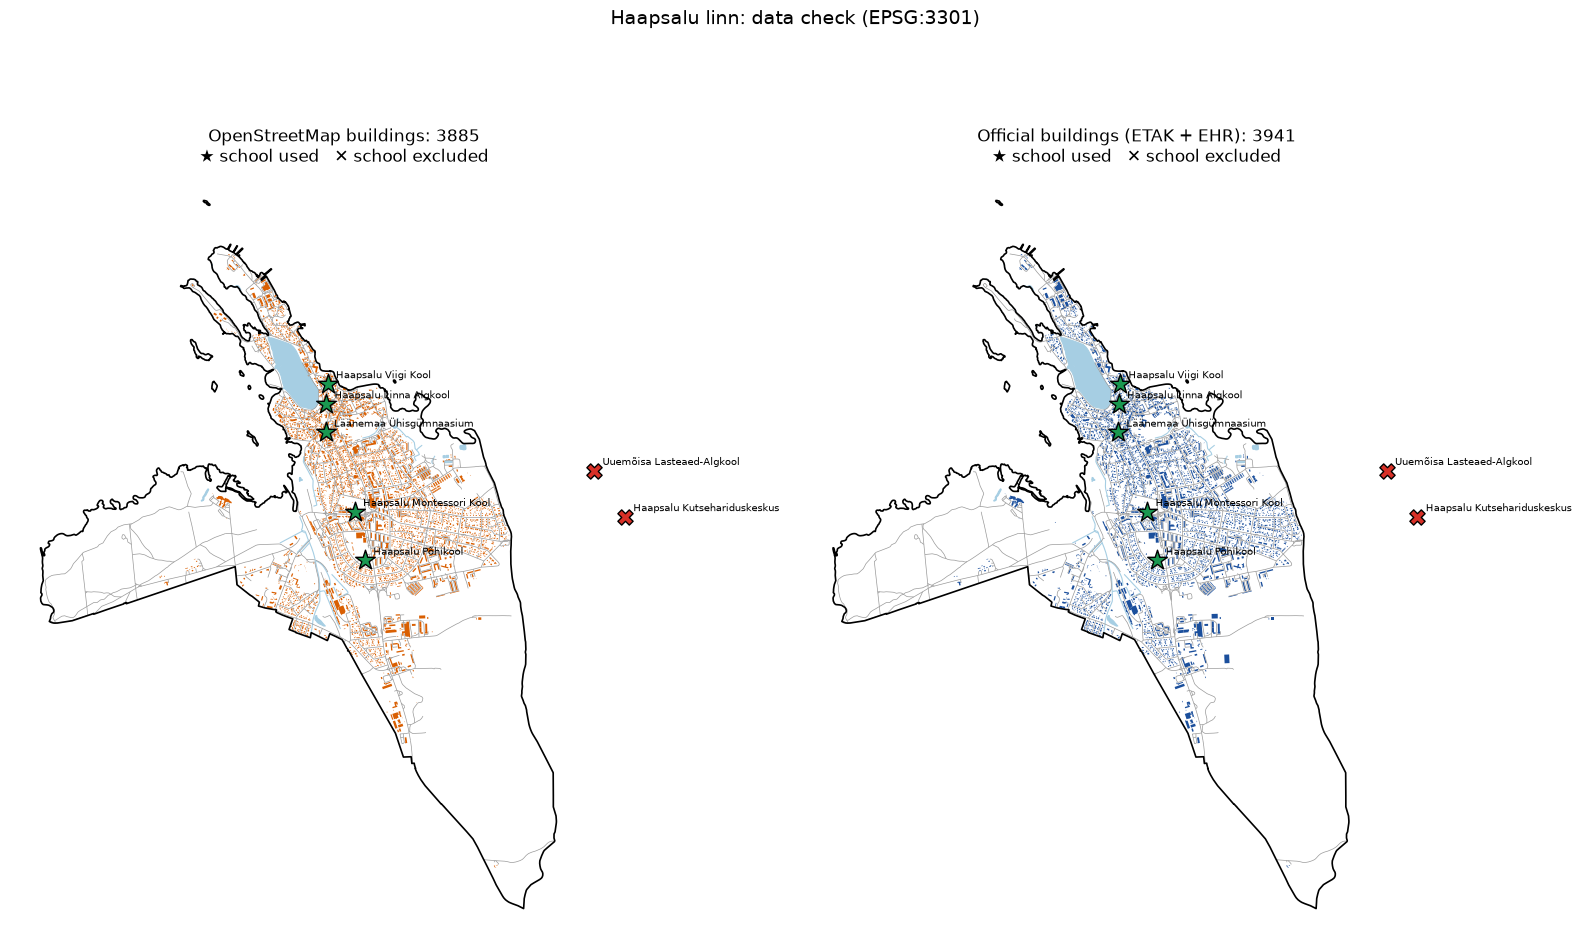

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 11), sharex=True, sharey=True)
xmin, ymin, xmax, ymax = boundary.total_bounds
for ax, (title, b, colour) in zip(axes, [("OpenStreetMap buildings", buildings_osm, "#d95f02"),
                                         ("Official buildings (ETAK + EHR)", buildings_off, "#1b4f9c")]):
    water.plot(ax=ax, color="#a6cee3", edgecolor="#a6cee3", linewidth=0.8)
    roads.plot(ax=ax, color="#999999", linewidth=0.5)
    b.plot(ax=ax, color=colour, linewidth=0)
    boundary.boundary.plot(ax=ax, color="black", linewidth=1.2)
    ehis[ehis["used"]].plot(ax=ax, color="#1a9850", marker="*", markersize=220, edgecolor="black", zorder=5)
    ehis[~ehis["used"]].plot(ax=ax, color="#d73027", marker="X", markersize=120, edgecolor="black", zorder=5)
    for r in ehis.itertuples():
        ax.annotate(r.name, (r.geometry.x, r.geometry.y), xytext=(6, 4), textcoords="offset points", fontsize=7)
    ax.set_xlim(xmin - 300, xmax + 1200)
    ax.set_ylim(ymin - 300, ymax + 300)
    ax.set_title(f"{title}: {len(b)}\n★ school used   ✕ school excluded")
    ax.set_axis_off()
fig.suptitle("Haapsalu linn: data check (EPSG:3301)", fontsize=14)
fig.tight_layout()
fig.savefig(DATA / "check_map.png", dpi=150)
plt.show()

## 2. City blocks

Blocks are cut with BlocksNet 1.0.0a9 (`blocksnet.blocks.cutting`), following its example
`examples/blocks/cutting.ipynb`. Inputs are read back from the saved `data/*.geojson` files,
so this section can be run on its own after section 1.

Decisions applied here (see `PLAN.md`):
- **No railway.** The Haapsalu line is closed, so `None` is passed instead of the railway layer.
- **Roads:** the BlocksNet road types plus `highway=service` (yard and access roads).
  Footways, paths, cycleways and steps are not used: they would cut the town into strips.
- **Islands without buildings are dropped:** no buildings and further than 20 m from every road
  (`data/blocks_dropped_islands.geojson`).
- **Slivers are dropped:** blocks without buildings and smaller than 500 m²
  (`data/blocks_dropped_slivers.geojson`).
- **Undeveloped blocks are kept** and marked `built_up = False`.
- **Large blocks** (over 1 km²) are kept and marked `large_block = True`, so that averages and
  the dashboard can treat them separately. The 1 km² threshold is preliminary.
- Dead-end streets are not extended and land-use outlines are not used for cutting.

### 2.1 Cutting

`preprocess_urban_objects` turns roads (lines) and water (lines and polygons) into the
line and polygon objects that cut the town polygon; `cut_urban_blocks` returns the blocks.
The optional block classifier of BlocksNet (it splits very large blocks) is not used here;
it is tried separately in a test run.

In [12]:
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

boundary_gdf = gpd.read_file(DATA / "boundary.geojson")[["geometry"]]
roads_gdf = gpd.read_file(DATA / "osm_roads.geojson")
water_gdf = gpd.read_file(DATA / "osm_water.geojson")
print("Road types used for cutting:", roads_gdf["highway"].value_counts().to_dict())

lines_gdf, polygons_gdf = preprocess_urban_objects(roads_gdf, None, water_gdf)  # None: no railway
blocks_all = cut_urban_blocks(boundary_gdf, lines_gdf, polygons_gdf)
print(f"Blocks cut by BlocksNet: {len(blocks_all)}")

C:\Users\nbale\dev\haapsalu-urban\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


2026-10-31 12:08:02.357 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema


2026-10-31 12:08:02.370 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema


2026-10-31 12:08:02.378 | WARNING  | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:53 - Creating empty railways


2026-10-31 12:08:02.383 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


2026-10-31 12:08:02.404 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema


... (3 outputs left out)

2026-10-31 12:08:02.461 | WARNING  | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:71 - Creating empty buildings


Road types used for cutting: {'residential': 385, 'service': 357, 'living_street': 117, 'track': 73, 'primary': 59, 'secondary': 27, 'tertiary': 22, 'unclassified': 5, 'secondary_link': 2, 'construction': 2, 'primary_link': 2, 'pedestrian': 2, 'tertiary_link': 1}


2026-10-31 12:08:02.826 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 398 blocks are successfully cut


Blocks cut by BlocksNet: 398


### 2.2 Built-up flag, islands, slivers and large blocks

For every block we count the buildings whose inside point lies in it, separately for the
official and the OSM layer. A block is **built up** if it has at least one building in
either layer. `building_share` is the footprint area of the official buildings divided by
the block area.

Two kinds of blocks without buildings are dropped, in this order:
1. **Island:** no buildings and further than 20 m from every road line
   (`ISLAND_MIN_ROAD_DISTANCE`), so it is not part of the street grid. There is no area limit.
2. **Sliver:** no buildings and area below 500 m² (`SLIVER_MAX_AREA`), typically a strip
   between roads.

Other blocks without buildings are kept with `built_up = False`. Blocks over 1 km²
(`LARGE_BLOCK_AREA`) get `large_block = True`.

In [13]:
ISLAND_MIN_ROAD_DISTANCE = 20   # m, islands are not next to a road
SLIVER_MAX_AREA = 500           # m², blocks without buildings below this area are slivers
LARGE_BLOCK_AREA = 1_000_000    # m², 1 km², preliminary threshold

blocks = blocks_all.copy()
blocks["area_m2"] = blocks.area.round(1)
points_off = gpd.GeoDataFrame({"footprint_m2": buildings_off.area}, geometry=buildings_off.representative_point(), crs=CRS)
points_osm = gpd.GeoDataFrame(geometry=buildings_osm.representative_point(), crs=CRS)
joined = gpd.sjoin(blocks[["geometry"]], points_off, predicate="contains")
blocks["n_buildings_official"] = joined.groupby(level=0).size().reindex(blocks.index).fillna(0).astype(int)
blocks["footprint_official_m2"] = joined.groupby(level=0)["footprint_m2"].sum().reindex(blocks.index).fillna(0).round(1)
blocks["n_buildings_osm"] = (gpd.sjoin(blocks[["geometry"]], points_osm, predicate="contains")
                             .groupby(level=0).size().reindex(blocks.index).fillna(0).astype(int))
blocks["building_share"] = (blocks["footprint_official_m2"] / blocks["area_m2"]).round(4)
blocks["built_up"] = (blocks["n_buildings_official"] + blocks["n_buildings_osm"]) > 0
blocks["road_distance_m"] = blocks.geometry.apply(lambda g: lines_gdf.distance(g).min()).round(1)

is_island = (~blocks["built_up"]) & (blocks["road_distance_m"] > ISLAND_MIN_ROAD_DISTANCE)
islands = blocks[is_island]
blocks = blocks[~is_island]

is_sliver = (~blocks["built_up"]) & (blocks["area_m2"] < SLIVER_MAX_AREA)
slivers = blocks[is_sliver]
blocks = blocks[~is_sliver].reset_index(drop=True)

blocks.insert(0, "block_id", range(1, len(blocks) + 1))
blocks["large_block"] = blocks["area_m2"] > LARGE_BLOCK_AREA
print(f"Dropped islands without buildings: {len(islands)} (total area {islands.area_m2.sum():,.0f} m²)")
print(f"Dropped slivers without buildings: {len(slivers)} (total area {slivers.area_m2.sum():,.0f} m²)")

Dropped islands without buildings: 9 (total area 24,327 m²)
Dropped slivers without buildings: 92 (total area 20,561 m²)


### 2.3 Save and summarise

Blocks are saved to `data/blocks.geojson` (EPSG:3301) with the columns `block_id`,
`area_m2`, building counts and footprint of the official buildings, `building_share`,
`road_distance_m`, `built_up` and `large_block`. The dropped islands and slivers are saved
to separate files, so the decisions can be checked.

In [14]:
SRC_BLOCKS = ("BlocksNet 1.0.0a9 cut_urban_blocks from OSM roads (incl. highway=service, no footway/path/cycleway/steps) "
              "and water, boundary EHAK Haapsalu linn; no railway")
save_layer(blocks, "blocks", SRC_BLOCKS + "; islands and slivers without buildings dropped",
           "derived, see other layers", "derived: the terms of the source layers apply")
save_layer(islands, "blocks_dropped_islands", "Blocks dropped as islands without buildings (no buildings, further than 20 m from any road)",
           "derived, see other layers", "derived: the terms of the source layers apply")
save_layer(slivers, "blocks_dropped_slivers", "Blocks without buildings smaller than 500 m² (slivers), dropped",
           "derived, see other layers", "derived: the terms of the source layers apply")

summary_blocks = pd.DataFrame({
    "blocks": [len(blocks), int(blocks.built_up.sum()), int((~blocks.built_up).sum()), int(blocks.large_block.sum())],
    "area_km2": [blocks.area_m2.sum() / 1e6, blocks[blocks.built_up].area_m2.sum() / 1e6,
                 blocks[~blocks.built_up].area_m2.sum() / 1e6, blocks[blocks.large_block].area_m2.sum() / 1e6]},
    index=["all blocks", "built_up = True", "built_up = False", "large_block = True"]).round(2)
display(summary_blocks)

top5 = blocks.nlargest(5, "area_m2").assign(area_km2=lambda d: (d.area_m2 / 1e6).round(2),
                                            building_share_pct=lambda d: (100 * d.building_share).round(1))
display(top5[["block_id", "area_km2", "n_buildings_official", "n_buildings_osm", "building_share_pct", "large_block"]])
print("Official buildings inside blocks:", int(blocks.n_buildings_official.sum()), "of", len(buildings_off),
      "| OSM:", int(blocks.n_buildings_osm.sum()), "of", len(buildings_osm))

blocks: 297 features -> data\blocks.geojson
blocks_dropped_islands: 9 features -> data\blocks_dropped_islands.geojson
blocks_dropped_slivers: 92 features -> data\blocks_dropped_slivers.geojson


,blocks,area_km2
all blocks,297,10.80
built_up = True,222,9.95
built_up = False,75,0.85
large_block = True,2,5.07


,block_id,area_km2,n_buildings_official,n_buildings_osm,building_share_pct,large_block
1,2,3.76,231,233,1.6,True
171,172,1.31,53,67,1.2,True
52,53,0.39,123,127,8.1,False
199,200,0.36,1,1,0.0,False
177,178,0.26,0,0,0.0,False


Official buildings inside blocks: 3941 of 3941 | OSM: 3884 of 3885


### 2.4 Check map

Blocks over roads, water and the town boundary. Built-up blocks are green, blocks without
buildings are orange, dropped islands are red, dropped slivers are purple. Large blocks
(`large_block`) have a thick blue outline. Saved to `data/blocks_check.png`.

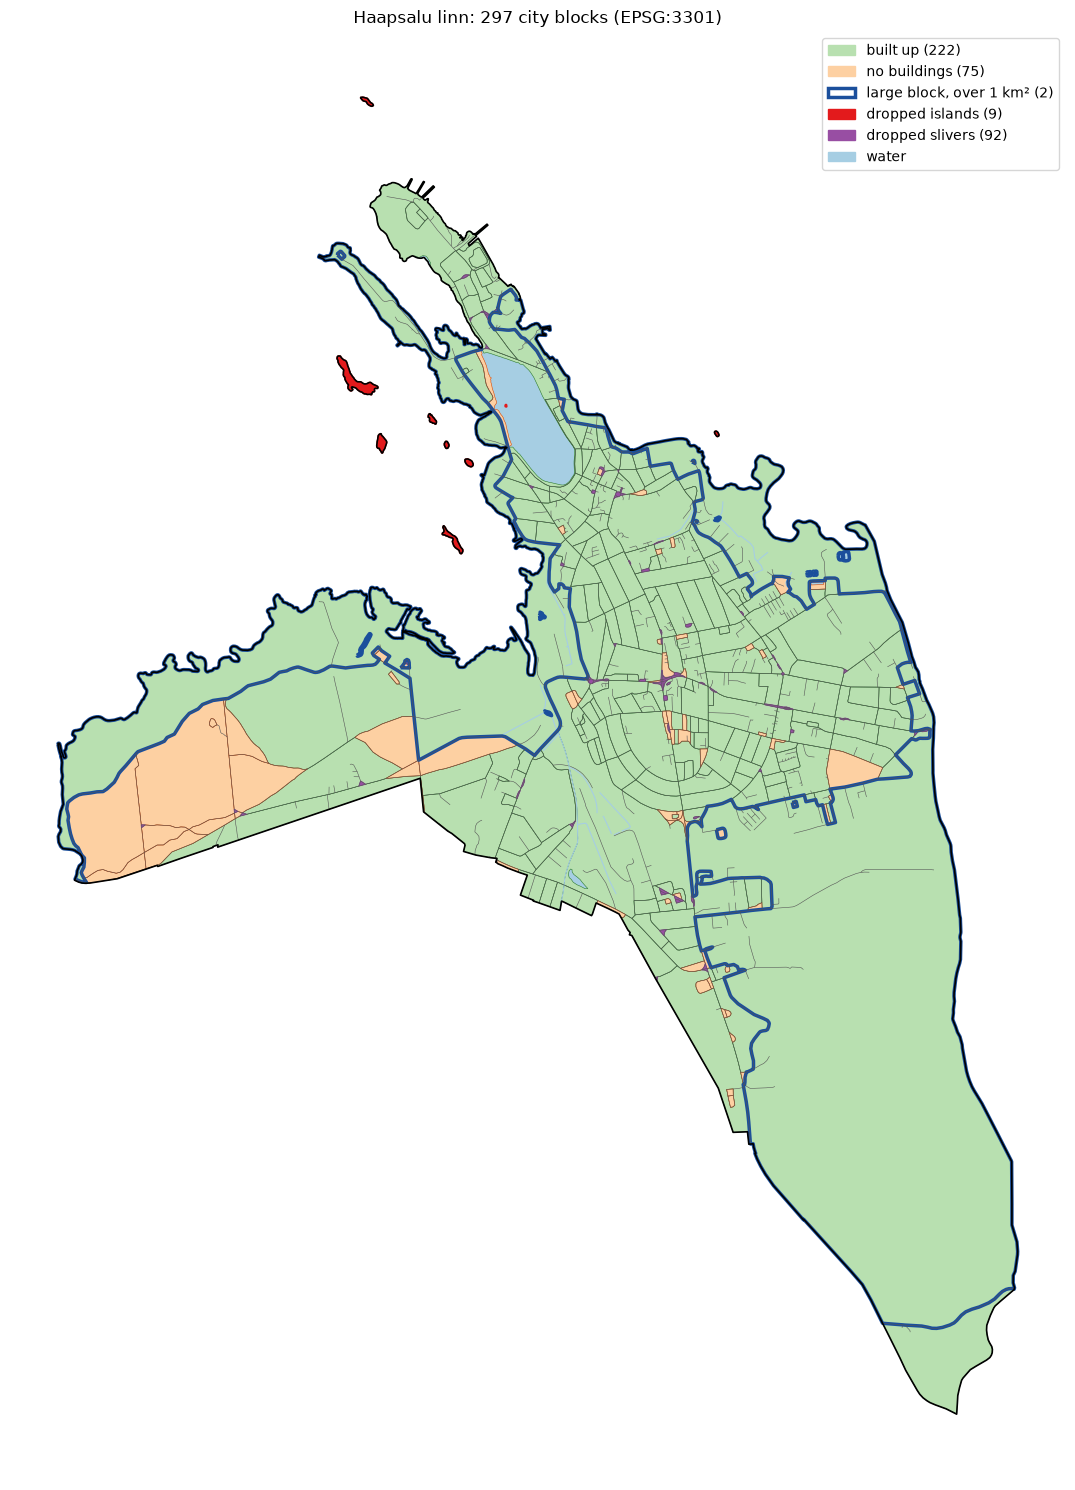

In [15]:
fig, ax = plt.subplots(figsize=(11, 15))
water.plot(ax=ax, color="#a6cee3", edgecolor="#a6cee3", linewidth=0.8)
blocks[blocks.built_up].plot(ax=ax, color="#b8e0b0", edgecolor="#2b7a2b", linewidth=0.4)
blocks[~blocks.built_up].plot(ax=ax, color="#fdd0a2", edgecolor="#d94801", linewidth=0.4)
blocks[blocks.large_block].boundary.plot(ax=ax, color="#1b4f9c", linewidth=2.5)
islands.plot(ax=ax, color="#e31a1c", edgecolor="#e31a1c", linewidth=1)
slivers.plot(ax=ax, color="#984ea3", edgecolor="#984ea3", linewidth=0.8)
roads.plot(ax=ax, color="#555555", linewidth=0.4)
boundary.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.legend(handles=[Patch(color="#b8e0b0", label=f"built up ({int(blocks.built_up.sum())})"),
                   Patch(color="#fdd0a2", label=f"no buildings ({int((~blocks.built_up).sum())})"),
                   Patch(facecolor="none", edgecolor="#1b4f9c", linewidth=2.5, label=f"large block, over 1 km² ({int(blocks.large_block.sum())})"),
                   Patch(color="#e31a1c", label=f"dropped islands ({len(islands)})"),
                   Patch(color="#984ea3", label=f"dropped slivers ({len(slivers)})"),
                   Patch(color="#a6cee3", label="water")], loc="upper right")
ax.set_title(f"Haapsalu linn: {len(blocks)} city blocks (EPSG:3301)")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(DATA / "blocks_check.png", dpi=150)
plt.show()

### 2.5 Update `data/SOURCES.md`

The same table as in 1.7, written again so that it also lists the block layers.

In [16]:
lines = ["# Data sources", "",
         "Generated by `notebook.ipynb`, sections 1 and 2. All layers are in EPSG:3301 (L-EST97).", "",
         "| Layer | File | Source | URL | Licence | Downloaded | Features |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for s in SOURCES:
    n = "" if s["features"] is None else s["features"]
    lines.append(f"| {s['layer']} | `{s['file']}` | {s['source']} | {s['url']} | {s['licence']} | {s['date']} | {n} |")
lines += ["", "Number of floors in building layers:", "",
          "| Layer | Buildings | With floors | Share, % |", "| --- | --- | --- | --- |"]
lines += [f"| {r.layer} | {r.buildings} | {r.with_floors} | {r._4} |" for r in floors.itertuples()]
lines += ["", "## Notes and decisions", "",
          f"- **Living area per person: {LIVING_AREA_PER_PERSON} m²** (Haapsalu linn, census 2021) = RL21218 total area "
          f"of occupied conventional dwellings ({dwell[HAAPSALU]:,} m²) / RL21003 population ({population:,}). "
          "This is the total useful floor area of dwellings, the same concept as the 30.1 m² for Estonia on the census "
          "page \"Housing arrangements\" (https://rahvaloendus.ee/en/results/housing-arrangements). It is the closest "
          "to BlocksNet's footprint × floors (gross floor area). The same calculation gives "
          f"{statistics['check_estonia_same_method_m2']} m² for Estonia, slightly below 30.1 m², because people in "
          "institutions are in the denominator. RL21807 (23.5 m² Estonia, "
          f"{rooms_area_per_person['Haapsalu linn (settlement)']} m² Haapsalu linn) is not used: it is about 78 % of "
          "the total area, which fits the floor area of rooms only (inferred; the table has no footnote).",
          "- **Limitation:** BlocksNet floor area is footprint × floors (gross floor area, with walls, stairs and "
          "non-residential floors), while 29.9 m² is a usable floor area per person. The population estimate is "
          "therefore expected to be higher than the official 9 595. The parameter is not tuned to the official figure.",
          "- **Railway:** `osm_railways` contains segments of the closed Haapsalu line; they are not used for block cutting.",
          "- **Schools:** only general-education schools inside Haapsalu linn are used (`schools.geojson`). "
          "Excluded: Haapsalu Kutsehariduskeskus (vocational), Uuemõisa Lasteaed-Algkool (Uuemõisa alevik) and "
          "Ridala Põhikool (Panga küla), both outside the settlement. EHIS gives students, not design capacity; "
          "students are used as capacity.",
          "- **OSM schools:** the duplicate outline of Haapsalu Põhikool inside its school grounds is removed.",
          "- **Buildings** (both layers) are kept whole if their inside point lies in the town, not cut at the boundary.",
          "- **Roads:** BlocksNet road types plus `highway=service`; no footway, path, cycleway or steps. The roads "
          "layer was downloaded again for this on the date shown in the table (the other OSM layers keep their date).",
          "- **Blocks:** cut with BlocksNet from OSM roads and water, no railway. Islands without buildings "
          "(no buildings, further than 20 m from any road, no area limit) are dropped (`blocks_dropped_islands`). "
          "Slivers (no buildings, under 500 m²) are dropped (`blocks_dropped_slivers`). Other blocks without buildings "
          "are kept with `built_up = False`. Blocks over 1 km² (preliminary threshold) have `large_block = True`.",
          "- **official_buildings.geojson:** the server row number `fid` is dropped and the rows are sorted by "
          "`ehr_gid`, then `etak_id`, so the file is identical between runs. Added columns: `footprint_m2` (geometry "
          "area), `floors` (registry `max_korruste_arv`, else `round(korgus_m / 3)` with minimum 1, else 1) and "
          "`floors_source` (`registry`, `height_3m`, `default_1`) and `is_dwelling` (at least one of five dwelling uses "
          "in `kaos_nimetus`; the whole building counts; cut text tails read as the full name for classification "
          "only). 3 m per floor is a conventional assumption; floors not from the registry are for density only, "
          "not for population.",
          "- **Frozen downloads:** every source is downloaded once; raw files stay in `data/raw/` (not in git) and later "
          "runs reuse them. The column *Downloaded* is the date of the first download (`data/download_dates.json`). "
          "To refresh a source, delete its raw file and its date entry. The date of the derived `blocks*` layers is the "
          "date of the last run.",
          "- **Official buildings, re-download check (2026-10-31):** the WFS layer was requested again one day after the "
          "first download. The result was identical: 3 941 buildings in town, 2 982 with `max_korruste_arv`, the same "
          "`etak_id` set, no floor value changed, latest `muutmisaeg` 2026-10-22 in both. Only the server's internal row "
          "number `fid` (3 903 buildings) and the order of the features differ; geometry and all other attributes are "
          "identical. OSM was not downloaded again: it is served from the local copy of the first download (3 885 "
          "buildings, 140 with `building:levels`)."]
lines += ["", "## Licences", "",
          "### Maa- ja Ruumiamet (EHAK settlement boundary, ETAK buildings with EHR data)", "",
          "Source: https://geoportaal.maaruum.ee/opendata-licence (English) and "
          "https://geoportaal.maaruum.ee/avaandmete-litsents (Estonian), licence dated 01.01.2025, "
          "read on 2026-10-31. The licence names the data of the Estonian Topographic Database; the ETAK download page "
          "says that downloading means accepting it. The EHAK page only says the data are open and asks for source and "
          "date. The WFS metadata record calls the terms \"CC BY 4.0 equivalent\"; the licence text itself is the "
          "Land Board's own and is quoted verbatim below.", "",
          "> **Republic of Estonia Land and Spatial Development Board opendata licence 01.01.2025**",
          "> ",
          "> *Licencee's rights*",
          "> ",
          "> The licensee receives the rights to use the data free of charge for an unspecified term, for to good purpose "
          "in accordance with laws and best practice. The licensee may produce derivatives of data, adapt and combine "
          "data with its own (or other) data, products or services, use the data for commercial or non-commercial "
          "purposes and redistribute data.",
          "> ",
          "> *Licensee's obligations*",
          "> ",
          "> The licensee obliges to refer to the origin of data when publishing and redistributing data. The reference "
          "must include the name of the licensor, the title of the data and the age of the data (or the date of data "
          "extraction), e.g.:",
          "> ",
          "> Base Map: Republic of Estonia Land and Spatial Development Board 2025",
          "> ",
          "> Map data by Republic of Estonia Land and Spatial Development Board 01.01.2025",
          "> ",
          "> The licensee obliges to attach the agreement or the reference (https://geoportaal.maaruum.ee/opendata-licence) "
          "to the agreement to data when distributing data to the third parties.",
          "> ",
          "> *Responsibility*",
          "> ",
          "> The data is licensed \"as is\" and the licensor excludes all representations, warranties, obligations and "
          "liabilities in relation to the data to the maximum extent permitted by law. The licensee agrees to use data "
          "with all its possible inaccuracies.", "",
          "Reference to use in publications (name of licensor, title of data, date of extraction): "
          "*ETAK buildings with EHR data and EHAK settlement boundary: Republic of Estonia Land and Spatial "
          "Development Board, extract 30.10.2026.*", "",
          "### OpenStreetMap", "",
          "ODbL 1.0, © OpenStreetMap contributors, https://www.openstreetmap.org/copyright (not re-read in this check).", "",
          "### Statistics Estonia and EHIS", "",
          "Terms of use not checked yet (Statistics Estonia) and not stated on the pages checked (EHIS open data)."]
(DATA / "SOURCES.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# Data sources

Generated by `notebook.ipynb`, sections 1 and 2. All layers are in EPSG:3301 (L-EST97).

| Layer | File | Source | URL | Licence | Downloaded | Features |
| --- | --- | --- | --- | --- | --- | --- |
| boundary | `data/boundary.geojson` | Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), Haapsalu linn, AKOOD 1692, export 2026-09-02 | https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip | Republic of Estonia Land and Spatial Development Board (Maa- ja Ruumiamet) opendata licence 01.01.2025, https://geoportaal.maaruum.ee/opendata-licence (the EHAK page itself only says: open data, cite source and date) | 2026-10-30 | 1 |
| osm_roads | `data/osm_roads.geojson` | OpenStreetMap, highway=* (BlocksNet example tags + highway=service; no footway, path, cycleway, steps) | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-31 | 1054 |
| osm_railways | `data/osm_railways.geojson` | OpenStreetMap, railway=rail 

## 3. Population check for the whole town

A check only, for the town as a whole; nothing is calculated per block and nothing is adjusted
to the official figure. The living area per person (29.9 m², census 2021) and the official
population (9 595, RL21003) come from `data/statistics.json`.

Two ways to estimate the population of the dwellings (`is_dwelling`), see section 1.3:
1. gross floor area from the geometry: sum of `footprint_m2 × floors`, divided by 29.9 m²;
2. net floor area from the Building Register: sum of `suletud_netopind`, divided by 29.9 m².

BlocksNet computes floor area as footprint × floors (gross, with walls and stairs), while 29.9 m²
is a usable area per person, so the first estimate is expected to be higher than the official
population (see the limitation in section 1.4).

In [17]:
stats = json.loads((DATA / "statistics.json").read_text(encoding="utf-8"))
AREA_PER_PERSON = stats["living_area_per_person_m2_used"]
OFFICIAL_POPULATION = stats["population_haapsalu_linn_2021"]

dwellings = buildings_off[buildings_off["is_dwelling"]]
gross_area = (dwellings["footprint_m2"] * dwellings["floors"]).sum()
net_area = dwellings["suletud_netopind"].sum()
not_registry = dwellings["floors_source"] != "registry"
footprint_ratio = (dwellings["footprint_m2"] / dwellings["ehitisalune_pind"])[dwellings["ehitisalune_pind"] > 0]

population_check = {
    "living_area_per_person_m2": AREA_PER_PERSON,
    "official_population_2021_RL21003": OFFICIAL_POPULATION,
    "dwellings": int(len(dwellings)),
    "dwellings_without_suletud_netopind": int(dwellings["suletud_netopind"].isna().sum()),
    "dwellings_with_floors_not_from_registry": int(not_registry.sum()),
    "gross_area_m2_footprint_x_floors": round(float(gross_area)),
    "net_area_m2_suletud_netopind": round(float(net_area)),
    "population_gross": round(float(gross_area / AREA_PER_PERSON)),
    "population_net": round(float(net_area / AREA_PER_PERSON)),
    "ratio_gross_to_official": round(float(gross_area / AREA_PER_PERSON / OFFICIAL_POPULATION), 3),
    "ratio_net_to_official": round(float(net_area / AREA_PER_PERSON / OFFICIAL_POPULATION), 3),
    "median_footprint_m2_over_ehitisalune_pind_dwellings": round(float(footprint_ratio.median()), 3),
    "dwellings_with_ehitisalune_pind": int(len(footprint_ratio)),
}
(DATA / "population_check_city.json").write_text(json.dumps(population_check, indent=2), encoding="utf-8")
pd.Series(population_check).to_frame("value")

,value
living_area_per_person_m2,29.900
official_population_2021_RL21003,9595.000
dwellings,1757.000
dwellings_without_suletud_netopind,1.000
dwellings_with_floors_not_from_registry,0.000
gross_area_m2_footprint_x_floors,723250.000
net_area_m2_suletud_netopind,495762.000
population_gross,24189.000
population_net,16581.000
ratio_gross_to_official,2.521
